# DS Challenge

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from collections import Counter
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

## The data

In [2]:
df = pd.read_csv('base_info_produtos.csv', sep='\t')

In [3]:
df.head()

,nome,tipo,marca,categoria,cor,modelo
0,Samsung UN40C6900 LED Plana 40 Polegadas,TV,Samsung,Eletrônicos,None,None
1,Sapateira Limeira Alta 30 Pares Tabaco - Polit...,Armario,Politorno,Casa e Decoração,None,None
2,Faqueiro Tramontina Inox Laguna 66906760 20,Faqueiro,Tramontina,Casa e Decoração,Inox,None
3,Cartucho de tinta HP 72 C9371A 130 Mls Ciano,Cartucho,HP,None,None,None
4,Bolsa Pure Evo Medium Grip branco e preto - Puma,Bolsa,Puma,Moda e Acessórios,None,None


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26241 entries, 0 to 26240
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   nome       26241 non-null  object
 1   tipo       26241 non-null  object
 2   marca      26241 non-null  object
 3   categoria  26241 non-null  object
 4   cor        26241 non-null  object
 5   modelo     26241 non-null  object
dtypes: object(6)
memory usage: 1.2+ MB


In [5]:
# df = df.replace({'None': None})

In [6]:
# df.info()

## Data viz

In [7]:
def plot_counts(series, n=25):
    """Plot the top n values of a series."""
    fig, ax = plt.subplots(figsize=(15, 5))
    m = series.value_counts()[:n]
    m.plot(kind='bar')
    plt.rc('font', size=14)
    plt.title(f'{series.name.capitalize()}', pad=15)
    plt.ylabel('Frequency', labelpad=15)
    plt.xticks(rotation=80)
    y_lim = ax.get_ylim()[1]
    for i, cnt in enumerate(m):
        plt.text(i, cnt, f' {cnt}', rotation=90, ha='center', 
                 va='top' if cnt > y_lim // 2 else 'bottom', color='white' if cnt > y_lim // 2 else 'black')

### Term frequencies

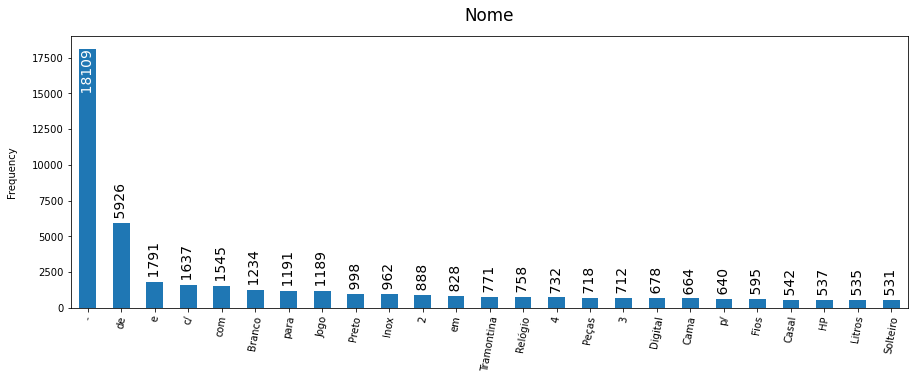

In [8]:
plot_counts(pd.Series(' '.join(df['nome']).split(), name='nome'))

Some of the most common terms are either nonalphanumeric characters or words that are probably irrelevant for our task (such as *de*, *com*, *para* etc.). We're going to have to address that. We can see that some numbers are also among the most common terms. Numbers are probably important for product matching (e.g.: *4G*, *8GB*, *iPhone 12*) so we're going to keep them as they are.

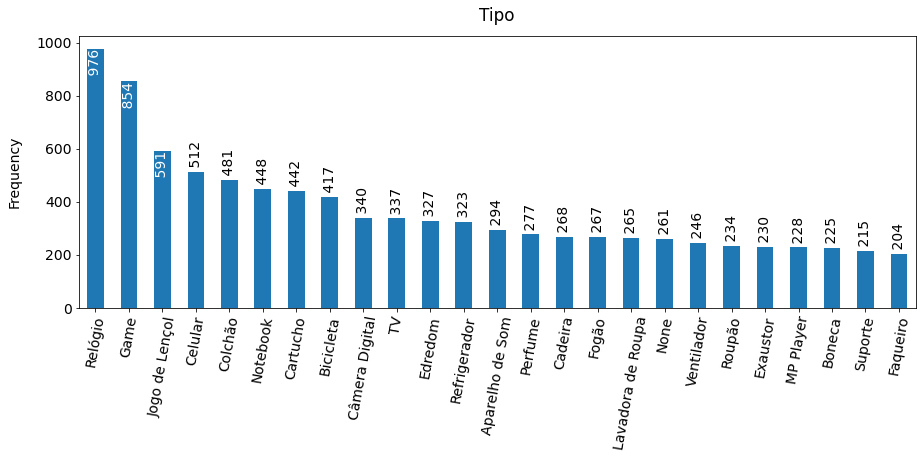

In [9]:
plot_counts(df['tipo'])

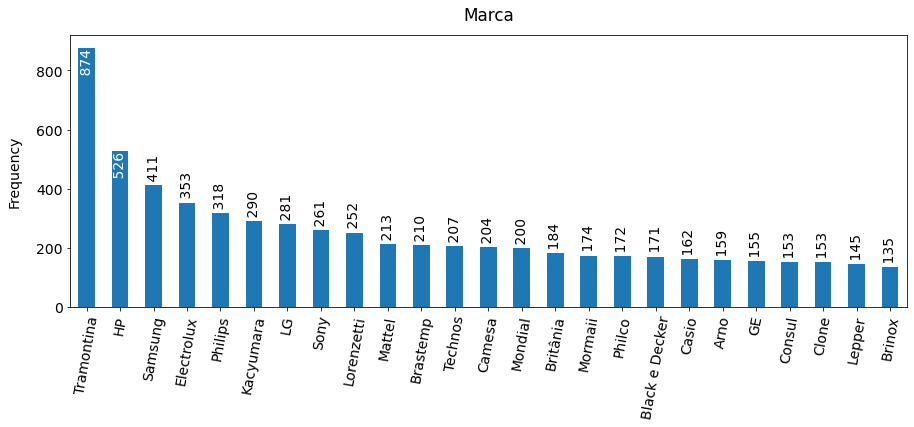

In [10]:
plot_counts(df['marca'])

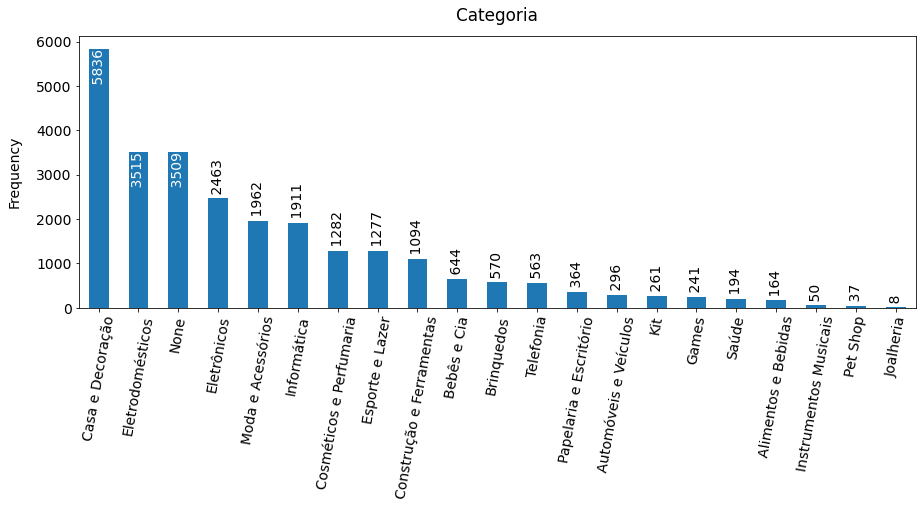

In [11]:
plot_counts(df['categoria'])

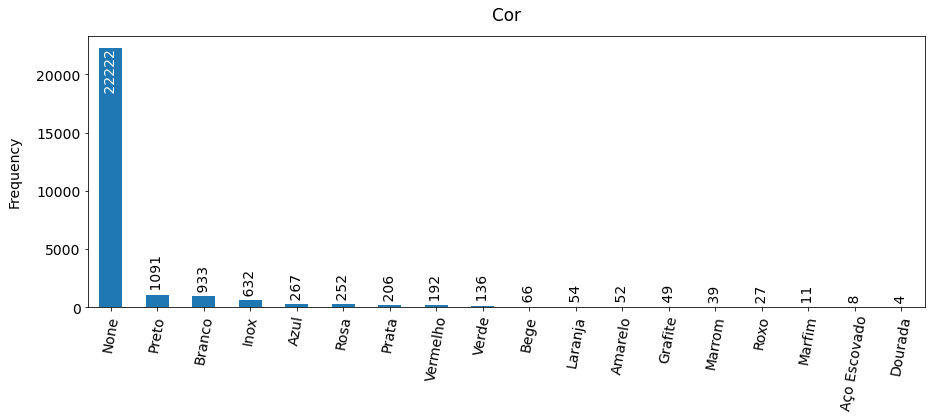

In [12]:
plot_counts(df['cor'])

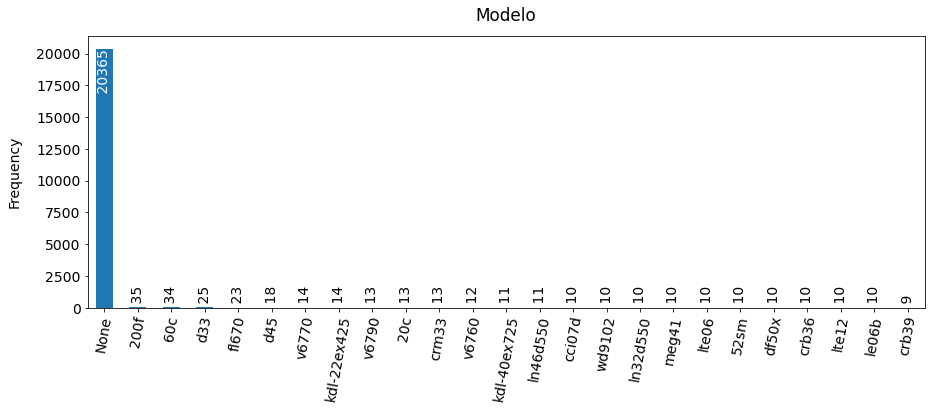

In [13]:
plot_counts(df['modelo'])

### Preprocessing

Before we go any further, we have to preprocess our data. Since all of our data consists of text data, we're going to apply the same steps to all of the columns.

We're going to:

1. Convert to lowercase.
2. Remove accent marks.
3. Remove non-alphanumeric characters.
4. Remove single character words.
5. Remove stops words.

In [14]:
import functools

def compose(*functions):
    return functools.reduce(lambda f, g: lambda x: f(g(x)), functions, lambda x: x)

def tolower(s):
    return s.str.lower()

def remove_accentmarks(s):
    return s.str.normalize('NFKD').str.encode('ascii', errors='ignore').str.decode('utf-8')

def remove_nonalpha(s):
    return s.replace('[^A-Za-z0-9]+', ' ', regex=True)

def remove_singlechar(s):
    return s.replace(r'\b[a-z]\b','', regex=True).str.replace(r'\s+', ' ', regex=True)

def remove_stopwords(s):
    return s.replace(r'\b(de|com|para|em)\b\s*', '', regex=True)

Let's apply the preprocessing and save the results to a new dataframe. Let's keep a copy of the original dataframe. We're going to use it to retrieve product data, when we're done with our model.

In [15]:
preprocessing = compose(remove_stopwords, remove_singlechar, remove_nonalpha, remove_accentmarks, tolower)

In [16]:
df_processed = df.apply(preprocessing)

In [17]:
df_processed.head()

,nome,tipo,marca,categoria,cor,modelo
0,samsung un40c6900 led plana 40 polegadas,tv,samsung,eletronicos,none,none
1,sapateira limeira alta 30 pares tabaco politorno,armario,politorno,casa decoracao,none,none
2,faqueiro tramontina inox laguna 66906760 20,faqueiro,tramontina,casa decoracao,inox,none
3,cartucho tinta hp 72 c9371a 130 mls ciano,cartucho,hp,none,none,none
4,bolsa pure evo medium grip branco preto puma,bolsa,puma,moda acessorios,none,none


## Model

Now we can start working on our model. Before we can feed our data to an algorithm we have to transform it from text to number, since in general machine learning algorithms don't know how to work with text data. In other words, we need to vectorize our data. One of the simplest and most used techniques is called *Bag of Words* in which documents are described by word occurrences. Basically, we're counting all the unique words in all of our documents, creating a new feature for each one of them and then, for each document, indicating which of these words are present in the document.

In a large corpus, some words will be very present hence carrying very little meaningful information about the actual contents of the document. If we were to feed the direct count data directly to our model those very frequent terms would shadow the frequencies of rarer yet more interesting terms.

In order to re-weight the count features, it is very common to use the tf–idf (term frequency–inverse document frequency) transform.

We can use a TfidfVectorizer to do all those steps.

In [18]:
ct = ColumnTransformer([
    ('nome_vect', TfidfVectorizer(max_features=1_000, ngram_range=(1,2)), 'nome'),
    ('tipo_vect', TfidfVectorizer(max_features=1_000, ngram_range=(1,1)), 'tipo'),
    ('marca_vect', TfidfVectorizer(max_features=1_000, ngram_range=(1,1)), 'marca'),
    ('categoria_vect', TfidfVectorizer(max_features=1_000, ngram_range=(1,2)), 'categoria'),
    ('cor_vect', TfidfVectorizer(max_features=1_000, ngram_range=(1,1)), 'cor'),
    ('modelo_vect', TfidfVectorizer(max_features=1_000, ngram_range=(1,1)), 'modelo'),
])

In [19]:
X_transformed = ct.fit_transform(df_processed)

In [20]:
X_transformed

<26241x3597 sparse matrix of type '<class 'numpy.float64'>'
	with 276624 stored elements in Compressed Sparse Row format>

In [21]:
print(X_transformed[0])

  (0, 71)	0.429127098837806
  (0, 584)	0.3783047396465559
  (0, 586)	0.4703578929483458
  (0, 756)	0.41363856395100873
  (0, 766)	0.3816102351142236
  (0, 849)	0.36711806876508557
  (0, 1513)	1.0
  (0, 2327)	1.0
  (0, 2553)	1.0
  (0, 2590)	1.0
  (0, 3352)	1.0


Now that we have our TF-IDF features we can implement a neighbor search to look for similar products. A metric commonly used for text is cosine similarity, so let's use that.

In [22]:
nn = NearestNeighbors(n_neighbors=10, metric='cosine')

In [23]:
nn.fit(X_transformed)

NearestNeighbors(metric='cosine', n_neighbors=10)

Let's perform a search.

In [24]:
def build_query(nome='None', tipo='None', marca='None', categoria='None', cor='None', modelo='None'):
    query = pd.DataFrame({
        'nome': [nome],
        'tipo': [tipo],
        'marca': [marca],
        'categoria': [categoria],
        'cor': [cor],
        'modelo': [modelo],
    })
    return query.apply(preprocessing)

In [25]:
def exec_query(query):
    return nn.kneighbors(ct.transform(query))[1][0]

In [26]:
results = exec_query(build_query('notebook samsung', 'notebook', 'samsung', 'informática'))

In [27]:
df.iloc[results]

,nome,tipo,marca,categoria,cor,modelo
18235,Notebook RV415-AD2 - Samsung,Notebook,Samsung,Informática,None,None
25095,Notebook NP300V4A-AD1 - Samsung,Notebook,Samsung,Informática,None,None
24712,Notebook Samsung SÃ©rie 9 c/ IntelÂ® Core i5 2...,Notebook,Samsung,Informática,None,None
1102,Notebook Samsung RF511SD6 c/ IntelÂ® Core i5 2...,Notebook,Samsung,Informática,None,None
25148,Notebook Samsung Q320 c/ IntelÂ® Core 2 Duo T6...,Notebook,Samsung,Informática,None,None
2455,Notebook R440 Core I5 4GB 640GB LED 14P Window...,Notebook,Samsung,Informática,None,None
5034,Notebook Samsung RV411-CD1 c/ IntelÂ® Core i3 ...,Notebook,Samsung,Informática,None,None
3764,Notebook Samsung RV415AD3 c/AMDÂ® Dual Core 3G...,Notebook,Samsung,Informática,None,None
11718,Notebook Samsung Shark SF410 c/ IntelÂ® Core i...,Notebook,Samsung,Informática,None,None
16457,Notebook Samsung NP300V4A-AD2 c/ IntelÂ® Core ...,Notebook,Samsung,Informática,None,None


We got very relevant results, although you may have noticed that we cheated a little. If we were to perform a search in real life, we would only provide the name of the product. Most people would probably not provide the category, and providing less information makes the results less reliable.

In [28]:
results = exec_query(build_query('notebook samsung'))

In [29]:
df.iloc[results]

,nome,tipo,marca,categoria,cor,modelo
12205,Whey Protein - Solaris Nutrition,Whey,Solaris Nutrition,None,None,None
23024,Scanner de Cartões de Visita Personal - CardScan,Scanner,CardScan,None,None,None
11808,Traktor Kontrol S4 - Native Instruments,Traktor,Native Instruments,None,None,None
22661,Pôster Michael Jackson,Pôster,Michael,None,None,None
9395,Brinco Borboleta na Argola em AÃ§o - Carlotha ...,Brinco,Carlotha Bolota,None,None,None
8523,"Pôster """"CoraÃ§Ã£o Valente"""" Mel Gibson",Pôster,Gibson,None,None,None
3069,Lenços umedecidos para limpeza de pele 3 em 1 ...,Lenço,Softys,None,None,None
24129,Ração p/ Pássaros Granulada de Banana - Zootekna,Ração,Zootekna,None,None,None
16776,Extreme Whey Protein - Solaris Nutrition,Whey,Solaris Nutrition,None,None,None
15134,Bull Motors Quadriciclo BK-QD01,Mini Quadriciculo,Bull Motors,None,None,None


Ouch! Not one of the results is relevant, but perhaps we can find a way to get more relavant results with less user provided information.

## More models

### Category

What if given a query we can predict the category of the product? Then we can feed the prediction to our search query. That would probably improve our results.

First, let's take a look the unique category values.

In [30]:
df['categoria'].value_counts()

Casa e Decoração            5836
Eletrodomésticos            3515
None                        3509
Eletrônicos                 2463
Moda e Acessórios           1962
Informática                 1911
Cosméticos e Perfumaria     1282
Esporte e Lazer             1277
Construção e Ferramentas    1094
Bebês e Cia                  644
Brinquedos                   570
Telefonia                    563
Papelaria e Escritório       364
Automóveis e Veículos        296
Kit                          261
Games                        241
Saúde                        194
Alimentos e Bebidas          164
Instrumentos Musicais         50
Pet Shop                      37
Joalheria                      8
Name: categoria, dtype: int64

Let's group some of the least common categories under a umbrella term.

In [31]:
df_copy = df.copy()

In [32]:
df_copy['categoria'] = df['categoria'].replace(['None', 'Instrumentos Musicais', 'Pet Shop', 'Joalheria'], 'Outros')

Since we are going to predict the category, let's drop the column from our dataset and create a target variable y.

In [33]:
X, y = df_copy.drop('categoria', axis=1), df_copy['categoria']

And let's apply the same preprocessing as before.

In [34]:
X_processed = X.apply(preprocessing)

We have to convert our labels to a number, in order for them to be useful.

In [35]:
le_cat = LabelEncoder()

In [36]:
y_transformed = le_cat.fit_transform(y)

Let's split our dataset into training and testing subsets and let's also stratify our datasets, using the labels, in order to mantain the same proportion of categories in both datasets.

In [37]:
X_train, X_test, y_train, y_test = train_test_split(X_processed, y_transformed, test_size=0.3, random_state=42, stratify=y_transformed)

In [38]:
X_train

,nome,tipo,marca,cor,modelo
10513,chaleira aco inox apito sem tampa 2 5 litros c...,chaleira,tramontina,none,none
291,guard rail suporte carrera,suporte,carrera,none,none
19778,adesivo motorola w375 coevoluaao permitida por...,adesivo,iskin,none,none
17108,quebra cabeca 150 pecas princesas ref 02164 grow,quebra cabeca,grow,none,none
2921,furadeira impacto ffi 01 127v mondial,furadeira parafusadeira,mondial,none,none
...,...,...,...,...,...
19185,houston bristol lance 26,bicicleta,bristol,prata,none
7035,lixadeira orbital 6 porter cable,lixadeira,porter cable,none,none
4798,mor iglu 4 pessoas,barraca,mor,none,none
9098,sabonete anti acne 90g granado,sabonete,granado,none,none


Let's do the same transformations as before, except this time we're going to exclude the category.

In [39]:
ct_nome = ColumnTransformer([
    ('nome_vect', TfidfVectorizer(max_features=1_000, ngram_range=(1,2)), 'nome'),
])

In [40]:
X_transformed = ct_nome.fit_transform(X_train)

In [41]:
X_transformed

<18368x1000 sparse matrix of type '<class 'numpy.float64'>'
	with 78579 stored elements in Compressed Sparse Row format>

Now we're ready to fit a classifier

In [42]:
clf_cat = XGBClassifier(use_label_encoder=False)

In [43]:
clf_cat.fit(X_transformed, y_train)

[16:34:45] WARNING: /Users/runner/miniforge3/conda-bld/xgboost-split_1631904775127/work/src/learner.cc:1095: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'multi:softprob' was changed from 'merror' to 'mlogloss'. Explicitly set eval_metric if you'd like to restore the old behavior.


XGBClassifier(base_score=0.5, booster='gbtree', colsample_bylevel=1,
              colsample_bynode=1, colsample_bytree=1, gamma=0, gpu_id=-1,
              importance_type='gain', interaction_constraints='',
              learning_rate=0.300000012, max_delta_step=0, max_depth=6,
              min_child_weight=1, missing=nan, monotone_constraints='()',
              n_estimators=100, n_jobs=8, num_parallel_tree=1,
              objective='multi:softprob', random_state=0, reg_alpha=0,
              reg_lambda=1, scale_pos_weight=None, subsample=1,
              tree_method='exact', use_label_encoder=False,
              validate_parameters=1, verbosity=None)

In [44]:
y_pred = clf_cat.predict(ct_nome.transform(X_test))

In [45]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=le_cat.classes_))

                          precision    recall  f1-score   support

     Alimentos e Bebidas       1.00      0.86      0.92        49
   Automóveis e Veículos       0.82      0.60      0.69        89
             Bebês e Cia       0.80      0.70      0.75       193
              Brinquedos       0.77      0.79      0.78       171
        Casa e Decoração       0.93      0.91      0.92      1751
Construção e Ferramentas       0.88      0.73      0.80       328
 Cosméticos e Perfumaria       0.91      0.80      0.85       385
        Eletrodomésticos       0.90      0.88      0.89      1055
             Eletrônicos       0.85      0.78      0.81       739
         Esporte e Lazer       0.88      0.81      0.84       383
                   Games       0.84      0.92      0.87        72
             Informática       0.83      0.82      0.82       574
                     Kit       0.70      0.45      0.55        78
       Moda e Acessórios       0.94      0.92      0.93       589
         

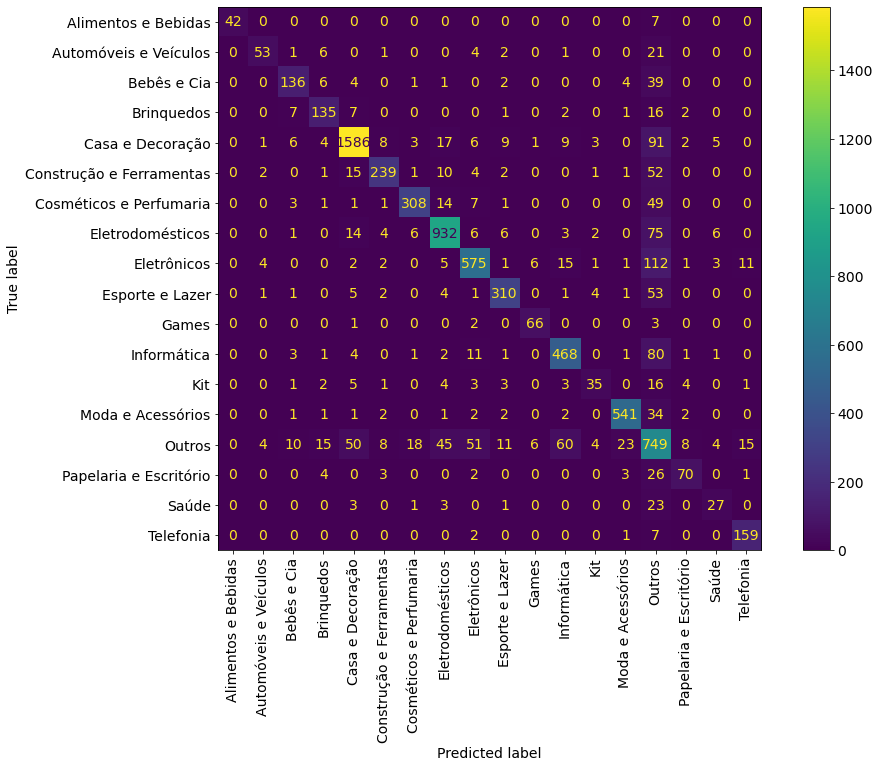

In [46]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

_, ax = plt.subplots(figsize=(15,10))
cm = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, 
                                             display_labels=le_cat.classes_, xticks_rotation='vertical')
plt.show()

In [47]:
query = build_query('notebook samsung')

In [48]:
query

,nome,tipo,marca,categoria,cor,modelo
0,notebook samsung,none,none,none,none,none


In [49]:
query['categoria'] = le_cat.inverse_transform(clf_cat.predict(ct_nome.transform(query)))[0]
query['categoria']

0    Informática
Name: categoria, dtype: object

In [50]:
results = exec_query(query)

In [51]:
df.iloc[results]

,nome,tipo,marca,categoria,cor,modelo
9196,Kit Wireless SWA-5000 / XAZ - Samsung,None,Samsung,Kit,None,None
23624,Cromus 200M MultiPonto,None,Cromus,Kit,None,None
22180,Kit Profissional Fittipaldi 17 Ferramentas - F...,None,Fender,Kit,None,None
2323,Visiontec C2 Monoponto,None,Visiontec,Kit,None,None
2941,Kit de Ferramentas Fittipaldi 102 PeÃ§as com M...,None,Fender,Kit,None,None
9338,Conj Camp 2 pec - 1 Fac 8 + 1 Chaira Amo fac +...,None,Tramontina,Kit,None,None
10754,Kit Reparo Multiuso - Mor,None,Pisc,Kit,None,None
10829,Cromus 200M Monoponto,None,Cromus,Kit,None,None
23076,Bomber TR5 - Triaxial 5,None,Shutt,Kit,None,None
15957,Positron QRx-P6960T,None,Positron,Kit,None,None


### Type

A little better, but not much, let's add a *type* model to our pipeline.

Let's restrict the labels to the top 20 most common and group the remaining ones under a single term.

In [52]:
df['tipo'].value_counts()[:20]

Relógio              976
Game                 854
Jogo de Lençol       591
Celular              512
Colchão              481
Notebook             448
Cartucho             442
Bicicleta            417
Câmera Digital       340
TV                   337
Edredom              327
Refrigerador         323
Aparelho de Som      294
Perfume              277
Cadeira              268
Fogão                267
Lavadora de Roupa    265
None                 261
Ventilador           246
Roupão               234
Name: tipo, dtype: int64

In [53]:
least_common = df['tipo'].value_counts()[20:].index.tolist()

In [54]:
df_copy['tipo'] = df['tipo'].replace(least_common, 'Outros')

In [55]:
df_copy.head()

,nome,tipo,marca,categoria,cor,modelo
0,Samsung UN40C6900 LED Plana 40 Polegadas,TV,Samsung,Eletrônicos,None,None
1,Sapateira Limeira Alta 30 Pares Tabaco - Polit...,Outros,Politorno,Casa e Decoração,None,None
2,Faqueiro Tramontina Inox Laguna 66906760 20,Outros,Tramontina,Casa e Decoração,Inox,None
3,Cartucho de tinta HP 72 C9371A 130 Mls Ciano,Cartucho,HP,Outros,None,None
4,Bolsa Pure Evo Medium Grip branco e preto - Puma,Outros,Puma,Moda e Acessórios,None,None


In [56]:
df_copy['tipo'].value_counts()

Outros               18081
Relógio                976
Game                   854
Jogo de Lençol         591
Celular                512
Colchão                481
Notebook               448
Cartucho               442
Bicicleta              417
Câmera Digital         340
TV                     337
Edredom                327
Refrigerador           323
Aparelho de Som        294
Perfume                277
Cadeira                268
Fogão                  267
Lavadora de Roupa      265
None                   261
Ventilador             246
Roupão                 234
Name: tipo, dtype: int64

In [57]:
X, y = df_copy.drop('tipo', axis=1), df_copy['tipo']

In [58]:
X_processed = X.apply(preprocessing)

In [59]:
le_tipo = LabelEncoder()

In [60]:
y_transformed = le_tipo.fit_transform(y)

In [61]:
X_train, X_test, y_train, y_test = train_test_split(X_processed, y_transformed, test_size=0.3, random_state=42, stratify=y_transformed)

In [62]:
clf_tipo = XGBClassifier(use_label_encoder=False)

In [63]:
clf_tipo.fit(ct_nome.transform(X_train), y_train)

[16:35:05] WARNING: /Users/runner/miniforge3/conda-bld/xgboost-split_1631904775127/work/src/learner.cc:1095: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'multi:softprob' was changed from 'merror' to 'mlogloss'. Explicitly set eval_metric if you'd like to restore the old behavior.


XGBClassifier(base_score=0.5, booster='gbtree', colsample_bylevel=1,
              colsample_bynode=1, colsample_bytree=1, gamma=0, gpu_id=-1,
              importance_type='gain', interaction_constraints='',
              learning_rate=0.300000012, max_delta_step=0, max_depth=6,
              min_child_weight=1, missing=nan, monotone_constraints='()',
              n_estimators=100, n_jobs=8, num_parallel_tree=1,
              objective='multi:softprob', random_state=0, reg_alpha=0,
              reg_lambda=1, scale_pos_weight=None, subsample=1,
              tree_method='exact', use_label_encoder=False,
              validate_parameters=1, verbosity=None)

In [64]:
y_pred = clf_tipo.predict(ct_nome.transform(X_test))

In [65]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=le_tipo.classes_))

                   precision    recall  f1-score   support

  Aparelho de Som       0.87      0.55      0.67        88
        Bicicleta       0.92      0.88      0.90       125
          Cadeira       0.93      0.71      0.81        80
         Cartucho       0.95      0.94      0.94       133
          Celular       0.97      0.99      0.98       154
          Colchão       0.94      0.94      0.94       144
   Câmera Digital       0.97      0.89      0.93       102
          Edredom       0.96      0.96      0.96        98
            Fogão       0.97      0.97      0.97        80
             Game       0.94      0.90      0.92       256
   Jogo de Lençol       0.99      0.99      0.99       177
Lavadora de Roupa       0.90      0.66      0.76        80
             None       0.73      0.46      0.57        78
         Notebook       0.84      0.81      0.83       135
           Outros       0.96      0.98      0.97      5425
          Perfume       0.98      1.00      0.99       

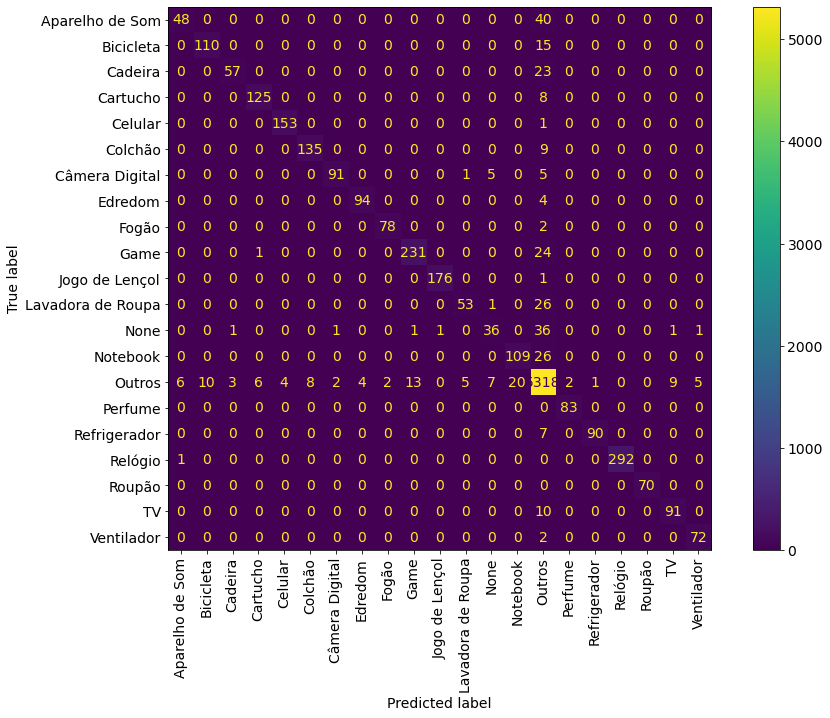

In [66]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

_, ax = plt.subplots(figsize=(15,10))
cm = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, 
                                             display_labels=le_tipo.classes_, xticks_rotation='vertical')
plt.show()

### Brand

Finally, let's add a *brand* model.

Once again, tet's restrict the labels to the top 20 most common and group the remaining ones under a single term.

In [67]:
df['marca'].value_counts()[:20]

Tramontina        874
HP                526
Samsung           411
Electrolux        353
Philips           318
Kacyumara         290
LG                281
Sony              261
Lorenzetti        252
Mattel            213
Brastemp          210
Technos           207
Camesa            204
Mondial           200
Britânia          184
Mormaii           174
Philco            172
Black e Decker    171
Casio             162
Arno              159
Name: marca, dtype: int64

In [68]:
least_common = df['marca'].value_counts()[20:].index.tolist()

In [69]:
df_copy['marca'] = df['marca'].replace(least_common, 'Outros')

In [70]:
df_copy.head()

,nome,tipo,marca,categoria,cor,modelo
0,Samsung UN40C6900 LED Plana 40 Polegadas,TV,Samsung,Eletrônicos,None,None
1,Sapateira Limeira Alta 30 Pares Tabaco - Polit...,Outros,Outros,Casa e Decoração,None,None
2,Faqueiro Tramontina Inox Laguna 66906760 20,Outros,Tramontina,Casa e Decoração,Inox,None
3,Cartucho de tinta HP 72 C9371A 130 Mls Ciano,Cartucho,HP,Outros,None,None
4,Bolsa Pure Evo Medium Grip branco e preto - Puma,Outros,Outros,Moda e Acessórios,None,None


In [71]:
df_copy['marca'].value_counts()

Outros            20619
Tramontina          874
HP                  526
Samsung             411
Electrolux          353
Philips             318
Kacyumara           290
LG                  281
Sony                261
Lorenzetti          252
Mattel              213
Brastemp            210
Technos             207
Camesa              204
Mondial             200
Britânia            184
Mormaii             174
Philco              172
Black e Decker      171
Casio               162
Arno                159
Name: marca, dtype: int64

In [72]:
X, y = df_copy.drop('marca', axis=1), df_copy['marca']

In [73]:
X_processed = X.apply(preprocessing)

In [74]:
le_marca = LabelEncoder()

In [75]:
y_transformed = le_marca.fit_transform(y)

In [76]:
X_train, X_test, y_train, y_test = train_test_split(X_processed, y_transformed, test_size=0.3, random_state=42, stratify=y_transformed)

In [77]:
clf_marca = XGBClassifier(use_label_encoder=False)

In [78]:
clf_marca.fit(ct_nome.transform(X_train), y_train)

[16:35:23] WARNING: /Users/runner/miniforge3/conda-bld/xgboost-split_1631904775127/work/src/learner.cc:1095: Starting in XGBoost 1.3.0, the default evaluation metric used with the objective 'multi:softprob' was changed from 'merror' to 'mlogloss'. Explicitly set eval_metric if you'd like to restore the old behavior.


XGBClassifier(base_score=0.5, booster='gbtree', colsample_bylevel=1,
              colsample_bynode=1, colsample_bytree=1, gamma=0, gpu_id=-1,
              importance_type='gain', interaction_constraints='',
              learning_rate=0.300000012, max_delta_step=0, max_depth=6,
              min_child_weight=1, missing=nan, monotone_constraints='()',
              n_estimators=100, n_jobs=8, num_parallel_tree=1,
              objective='multi:softprob', random_state=0, reg_alpha=0,
              reg_lambda=1, scale_pos_weight=None, subsample=1,
              tree_method='exact', use_label_encoder=False,
              validate_parameters=1, verbosity=None)

In [79]:
y_pred = clf_marca.predict(ct_nome.transform(X_test))

In [80]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred, target_names=le_marca.classes_))

                precision    recall  f1-score   support

          Arno       1.00      0.98      0.99        48
Black e Decker       1.00      0.96      0.98        51
      Brastemp       1.00      0.98      0.99        63
      Britânia       0.98      0.95      0.96        55
        Camesa       1.00      1.00      1.00        61
         Casio       1.00      1.00      1.00        49
    Electrolux       1.00      0.97      0.99       106
            HP       0.98      0.98      0.98       158
     Kacyumara       0.97      0.99      0.98        87
            LG       0.97      0.99      0.98        84
    Lorenzetti       1.00      0.99      0.99        76
        Mattel       0.95      0.97      0.96        64
       Mondial       1.00      0.98      0.99        60
       Mormaii       0.98      0.96      0.97        52
        Outros       0.99      1.00      0.99      6186
        Philco       0.98      1.00      0.99        52
       Philips       0.98      0.93      0.95  

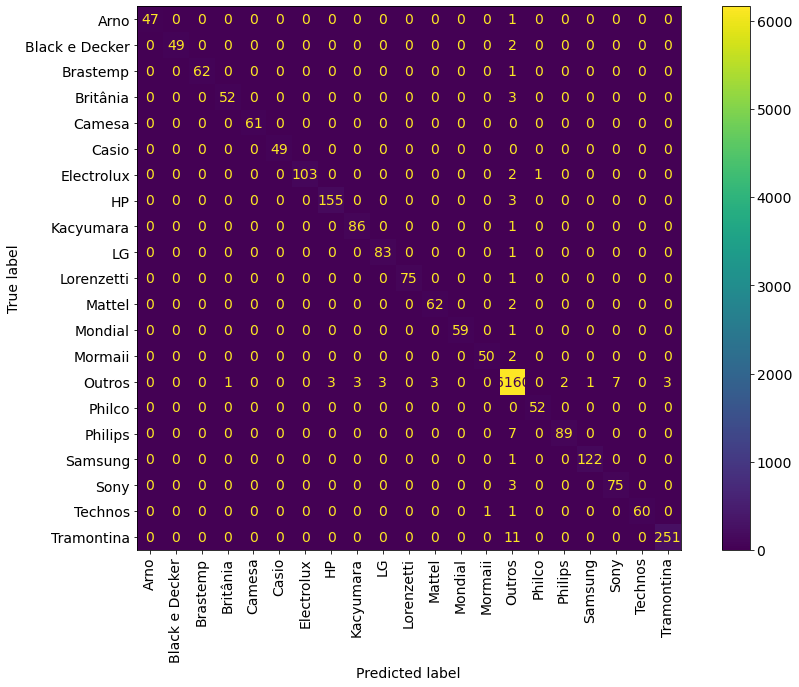

In [81]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

_, ax = plt.subplots(figsize=(15,10))
cm = ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax, 
                                             display_labels=le_marca.classes_, xticks_rotation='vertical')
plt.show()

## Putting it all together

Now, when a user submit a query we combine all of our models outputs to retrieve the product(s).

In [82]:
query = build_query('notebook samsung')
query

,nome,tipo,marca,categoria,cor,modelo
0,notebook samsung,none,none,none,none,none


In [83]:
query['categoria'] = le_cat.inverse_transform(clf_cat.predict(ct_nome.transform(query)))[0]
query

,nome,tipo,marca,categoria,cor,modelo
0,notebook samsung,none,none,Informática,none,none


In [84]:
query['marca'] = le_marca.inverse_transform(clf_marca.predict(ct_nome.transform(query)))[0]
query

,nome,tipo,marca,categoria,cor,modelo
0,notebook samsung,none,Samsung,Informática,none,none


In [85]:
query['tipo'] = le_tipo.inverse_transform(clf_tipo.predict(ct_nome.transform(query)))[0]
query

,nome,tipo,marca,categoria,cor,modelo
0,notebook samsung,Notebook,Samsung,Informática,none,none


In [86]:
results = exec_query(query)

In [87]:
df.iloc[results]

,nome,tipo,marca,categoria,cor,modelo
18235,Notebook RV415-AD2 - Samsung,Notebook,Samsung,Informática,None,None
25095,Notebook NP300V4A-AD1 - Samsung,Notebook,Samsung,Informática,None,None
24712,Notebook Samsung SÃ©rie 9 c/ IntelÂ® Core i5 2...,Notebook,Samsung,Informática,None,None
1102,Notebook Samsung RF511SD6 c/ IntelÂ® Core i5 2...,Notebook,Samsung,Informática,None,None
25148,Notebook Samsung Q320 c/ IntelÂ® Core 2 Duo T6...,Notebook,Samsung,Informática,None,None
2455,Notebook R440 Core I5 4GB 640GB LED 14P Window...,Notebook,Samsung,Informática,None,None
5034,Notebook Samsung RV411-CD1 c/ IntelÂ® Core i3 ...,Notebook,Samsung,Informática,None,None
3764,Notebook Samsung RV415AD3 c/AMDÂ® Dual Core 3G...,Notebook,Samsung,Informática,None,None
11718,Notebook Samsung Shark SF410 c/ IntelÂ® Core i...,Notebook,Samsung,Informática,None,None
16457,Notebook Samsung NP300V4A-AD2 c/ IntelÂ® Core ...,Notebook,Samsung,Informática,None,None


## Questions

Now we can finally answer the proposed questions.

### a) Dados dois produtos, qual a probabilidade de eles serem o mesmo produto?

### b) Dado um nome de produto, como recuperar as informações de ​tipo​, ​categoria​, ​marca​, cor e ​modelo​? Caso o produto não apresente a informação, o sistema deve retornar None.

Given the description, we can use our models to perform a search and then we return the *closest* match.

In [88]:
def build_query(nome='None', tipo='None', marca='None', categoria='None', cor='None', modelo='None'):
    query = pd.DataFrame({
        'nome': [nome],
        'tipo': [tipo],
        'marca': [marca],
        'categoria': [categoria],
        'cor': [cor],
        'modelo': [modelo],
    })
    query = query.apply(preprocessing)
    query['categoria'] = le_cat.inverse_transform(clf_cat.predict(ct_nome.transform(query)))[0]
    query['marca'] = le_marca.inverse_transform(clf_marca.predict(ct_nome.transform(query)))[0]
    query['tipo'] = le_tipo.inverse_transform(clf_tipo.predict(ct_nome.transform(query)))[0]
    return query

In [89]:
query = build_query('notebook sony 4 GB')
query

,nome,tipo,marca,categoria,cor,modelo
0,notebook sony 4 gb,Notebook,Sony,Informática,none,none


In [90]:
def get_closest(query):
    return nn.kneighbors(ct.transform(query))[1][0][0]

In [91]:
df.iloc[get_closest(query)]

nome         Notebook Sony Vaio VPC-SB35FB Preto - Sony
tipo                                           Notebook
marca                                              Sony
categoria                                   Informática
cor                                                None
modelo                                             None
Name: 1132, dtype: object

### c) Como usar a solução de matching para retornar os produtos mais relevantes para uma busca simples de um cliente do site? Exemplo de busca: ​notebook sony 4 GB​. Observação: adapte a solução de matching criada para resolver este item; não é necessário criar um sistema ou API.

We can adapt our previous solution to return the top 10 (the number of neighbors we selected when we created our model) best matchings.

In [92]:
def get_all(query):
    return nn.kneighbors(ct.transform(query))[1][0]

In [93]:
df.iloc[get_all(query)]

,nome,tipo,marca,categoria,cor,modelo
1132,Notebook Sony Vaio VPC-SB35FB Preto - Sony,Notebook,Sony,Informática,None,None
20293,Notebook Sony Vaio VPCSA35GB/SI prata - Sony,Notebook,Sony,Informática,None,None
2722,"Notebook Sony AMD Phenom? II Triple-Core P820,...",Notebook,Sony,Informática,None,None
17753,Notebook Sony VAIO EE23EB/WI Athlon® II Dual C...,Notebook,Sony,Informática,None,None
16400,Notebook Vaio S110 Core I3 2.13GHZ 4GB 500GB 1...,Notebook,Sony,Informática,None,None
19184,Notebook VPCEE43EB/WI Dual Core P360 4GB 500GB...,Notebook,Sony,Informática,None,None
9090,Note Vaio YB35AB-P Amd Dc 2Gb 500Gb Led11 W7S ...,Notebook,Sony,Eletrônicos,None,None
22387,Note Vaio YB35AB-S Amd Dc 2Gb 500Gb Led11 W7S ...,Notebook,Sony,Eletrônicos,None,None
19757,Notebook Sony VAIO SA25GB/SI - Sony,Processador,Sony,Informática,None,None
18930,Notebook Sony VAIO VPCF215FB/BI - Sony,Processador,Sony,Informática,None,None


## Conclusion

There still is a lot to be done. So far, we basically created models using their default parameters. We can improve each of them by optimizing their hyperparameters. We can try and create other features, we can better look for inconsistencies in our data, and so on. But we still have a good working solution.